# Partition splines

Fits the GAM separately to three disjoint random partitions of the data and exports the result for the partition plot (`partition_plots.ipynb`).

- The smoothing parameter of each partition is the full-data CV optimum scaled by the partition's fraction of the data.
- Each partition is z-scored on its own before fitting.
- Output: `adjusted_lambda_splines.pkl` in the output directory.

# Load Data

In [1]:
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.api as sm
import statsmodels.formula.api as smf
from pygam import LinearGAM
from pygam.terms import s, te
from scipy.interpolate import BSpline
from scipy.stats import t, ttest_1samp
from sklearn.metrics import mean_squared_error
from sklearn.model_selection import KFold
from statsmodels.tools.sm_exceptions import ConvergenceWarning
from tqdm.auto import tqdm

''' ---------------------------------------------------------------------------
    File description
'''

data = np.load(Path("..") / "data" / "mechanical_fingerprint.npz")

params = ["A", "B", "alpha", "beta", "E", "gamma"]
dirs = ["x", "y"]

log_params = {"A", "B", "E"}

dfs = {}

symmetry_x = 162.5

''' ---------------------------------------------------------------------------
    Symmetry and applying logarithm
'''

for d in dirs:
    coords_key = "coords_x_trans_ds_2" if d == "x" else "coords_y_trans_ds_2"
    coords = data[coords_key]

    df_d = pd.DataFrame({
        "cell_idx": data["cell_idx"],
        "cell_label": data["cell_label_in_day_folder"],
        "x_pos": coords[:, 0] - symmetry_x,
        "y_pos": coords[:, 1],
    })

    for p in params:
        values = data[f"{p}_{d}"]

        if p in log_params:
            df_d[f"log{p}"] = np.log(values)
        else:
            df_d[p] = values

    dfs[d] = df_d

''' ---------------------------------------------------------------------------
    Cleanup
'''

df_x = dfs["x"].replace([np.inf, -np.inf], np.nan).dropna()
df_y = dfs["y"].replace([np.inf, -np.inf], np.nan).dropna()

''' ---------------------------------------------------------------------------
    Cell Boundary Shape
'''

border_data = np.load(Path("..") / "data" / "actin_nucleus_borders.npz")
border_x = border_data['actin_border_x'] - symmetry_x
border_y = border_data['actin_border_y']

# Select Channel

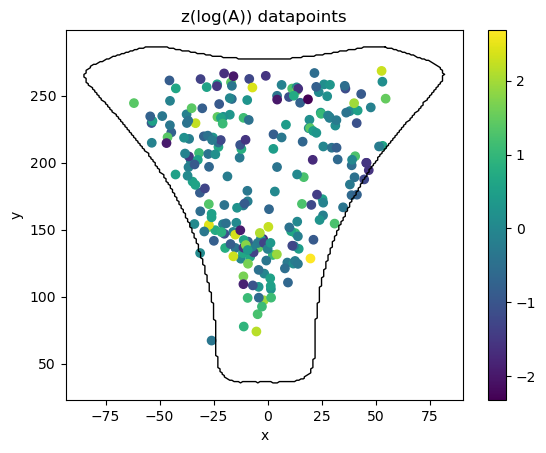

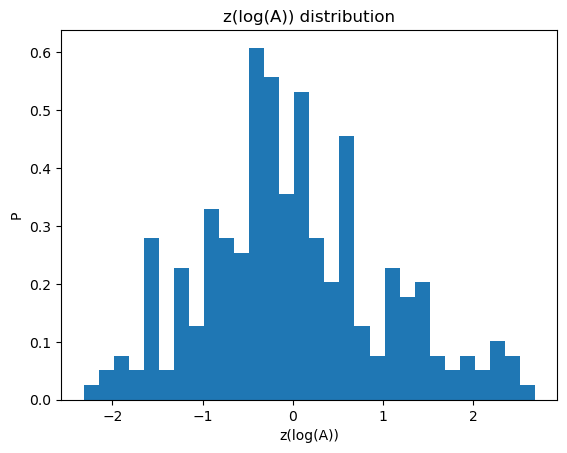

In [2]:
F_name = 'z(log(A))' # 'q1', 'z(log(A))', or 'z(log(E))'
df = df_x     # df_x or df_y


''' Python names for easy access '''

x = df.x_pos.to_numpy()
y = df.y_pos.to_numpy()

logA = df.logA.to_numpy()
logB = df.logB.to_numpy()
alpha = df.alpha.to_numpy()
beta = df.beta.to_numpy()
logE = df.logE.to_numpy()
gamma = df.gamma.to_numpy()

''' z normalized fields '''

logA = (logA - logA.mean()) / logA.std()
logB = (logB - logB.mean()) / logB.std()
alpha = (alpha - alpha.mean()) / alpha.std()
beta = (beta - beta.mean()) / beta.std()
logE = (logE - logE.mean()) / logE.std()
gamma = (gamma - gamma.mean()) / gamma.std()

q1 = (
    0.1688 * logA
    + 0.2758 * logB
    + 0.0091 * logE
    + 0.2694 * alpha
    + 0.2747 * beta
    + 0.0021 * gamma
)

''' Fied selection '''

FIELDS = {'q1': q1, 'z(log(A))': logA, 'z(log(E))': logE}
F = FIELDS[F_name]

''' Basic plotting '''

plt.scatter(x, y, c=F)
plt.xlabel("x")
plt.ylabel("y")
plt.title(f"{F_name} datapoints")
plt.colorbar()
plt.plot(border_x, border_y, '-k', lw=1)
plt.show()

plt.hist(F, bins=30, density=True)
plt.xlabel(F_name)
plt.ylabel("P")
plt.title(f"{F_name} distribution")
plt.show()

# Full-data lambda search and partition GAMs

In [3]:
n_splines = 15
n_folds = 5
n_independent_partitions = 3

lambda_grid = np.logspace(-5, 3, 30)

X = np.column_stack([x, y])

x_domain = np.concatenate([
    x,
    -x,
    border_x,
    -border_x,
])

y_domain = np.concatenate([
    y,
    border_y,
])

x_min = np.min(x_domain)
x_max = np.max(x_domain)
y_min = np.min(y_domain)
y_max = np.max(y_domain)

x_pad = 0.02 * (x_max - x_min)
y_pad = 0.02 * (y_max - y_min)

edge_knots = [
    [x_min - x_pad, x_max + x_pad],
    [y_min - y_pad, y_max + y_pad],
]

kf = KFold(
    n_splits=n_folds,
    shuffle=True,
    random_state=42,
)

splits = list(kf.split(X))

constant_fold_mse = []

for train_idx, val_idx in splits:
    F_constant = np.full(
        len(val_idx),
        np.mean(F[train_idx]),
    )

    constant_fold_mse.append(
        mean_squared_error(
            F[val_idx],
            F_constant,
        )
    )

constant_cv_mse = np.mean(constant_fold_mse)
constant_cv_std = np.std(constant_fold_mse)

mean_mse = []
std_mse = []

for lam in tqdm(
    lambda_grid,
    desc="Full-data lambda grid search",
):
    fold_mse = []

    for train_idx, val_idx in splits:
        x_train = x[train_idx]
        y_train = y[train_idx]
        F_train = F[train_idx]

        x_train_sym = np.concatenate([
            x_train,
            -x_train,
        ])

        y_train_sym = np.concatenate([
            y_train,
            y_train,
        ])

        F_train_sym = np.concatenate([
            F_train,
            F_train,
        ])

        X_train_sym = np.column_stack([
            x_train_sym,
            y_train_sym,
        ])

        X_val = np.column_stack([
            x[val_idx],
            y[val_idx],
        ])

        gam_cv = LinearGAM(
            te(
                0,
                1,
                n_splines=[n_splines, n_splines],
                lam=[lam, lam],
                edge_knots=edge_knots,
            )
        ).fit(
            X_train_sym,
            F_train_sym,
        )

        F_val_pred = gam_cv.predict(X_val)

        fold_mse.append(
            mean_squared_error(
                F[val_idx],
                F_val_pred,
            )
        )

    mean_mse.append(np.mean(fold_mse))
    std_mse.append(np.std(fold_mse))

mean_mse = np.asarray(mean_mse)
std_mse = np.asarray(std_mse)

best_idx = np.argmin(mean_mse)
worst_idx = np.argmax(mean_mse)

best_lam = lambda_grid[best_idx]
worst_lam = lambda_grid[worst_idx]

print("best lambda:", best_lam)
print("best CV MSE:", mean_mse[best_idx])
print("best CV RMSE:", np.sqrt(mean_mse[best_idx]))

print("worst lambda:", worst_lam)
print("worst CV MSE:", mean_mse[worst_idx])
print("worst CV RMSE:", np.sqrt(mean_mse[worst_idx]))

print("constant CV MSE:", constant_cv_mse)
print("constant CV RMSE:", np.sqrt(constant_cv_mse))

independent_kf = KFold(
    n_splits=n_independent_partitions,
    shuffle=True,
    random_state=42,
)

independent_partition_indices = [
    subset_idx.copy()
    for _, subset_idx in independent_kf.split(X)
]

independent_gams = []

for partition_id, subset_idx in enumerate(
    independent_partition_indices,
    start=1,
):
    x_subset = x[subset_idx]
    y_subset = y[subset_idx]
    F_subset = F[subset_idx]

    F_subset_mean = np.mean(F_subset)
    F_subset_std = np.std(F_subset)

    if F_subset_std == 0:
        F_subset_std = 1.0

    F_subset_z = (
        F_subset - F_subset_mean
    ) / F_subset_std

    x_subset_sym = np.concatenate([
        x_subset,
        -x_subset,
    ])

    y_subset_sym = np.concatenate([
        y_subset,
        y_subset,
    ])

    F_subset_z_sym = np.concatenate([
        F_subset_z,
        F_subset_z,
    ])

    X_subset_sym = np.column_stack([
        x_subset_sym,
        y_subset_sym,
    ])

    partition_fraction = (
        len(subset_idx) / len(X)
    )

    partition_lam = (
        best_lam * partition_fraction
    )

    gam_subset = LinearGAM(
        te(
            0,
            1,
            n_splines=[n_splines, n_splines],
            lam=[
                partition_lam,
                partition_lam,
            ],
            edge_knots=edge_knots,
        )
    ).fit(
        X_subset_sym,
        F_subset_z_sym,
    )

    X_subset = np.column_stack([
        x_subset,
        y_subset,
    ])

    F_subset_fit_z = gam_subset.predict(
        X_subset
    )

    independent_gams.append({
        "partition_id": partition_id,
        "subset_idx": subset_idx.copy(),
        "gam": gam_subset,
        "lam": partition_lam,
        "sample_fraction": partition_fraction,
        "F_mean": F_subset_mean,
        "F_std": F_subset_std,
        "F_z": F_subset_z.copy(),
        "F_fit_z": F_subset_fit_z.copy(),
    })

x_sym = np.concatenate([
    x,
    -x,
])

y_sym = np.concatenate([
    y,
    y,
])

F_sym = np.concatenate([
    F,
    F,
])

X_sym = np.column_stack([
    x_sym,
    y_sym,
])

gam_best = LinearGAM(
    te(
        0,
        1,
        n_splines=[
            n_splines,
            n_splines,
        ],
        lam=[
            best_lam,
            best_lam,
        ],
        edge_knots=edge_knots,
    )
).fit(
    X_sym,
    F_sym,
)

gam_worst = LinearGAM(
    te(
        0,
        1,
        n_splines=[
            n_splines,
            n_splines,
        ],
        lam=[
            worst_lam,
            worst_lam,
        ],
        edge_knots=edge_knots,
    )
).fit(
    X_sym,
    F_sym,
)

X_data = np.column_stack([
    x,
    y,
])

F_fit_best = gam_best.predict(
    X_data
)

F_fit_worst = gam_worst.predict(
    X_data
)

constant_value = np.mean(F)

F_fit_constant = np.full_like(
    F,
    constant_value,
    dtype=float,
)

print(
    "best effective DoF:",
    gam_best.statistics_["edof"],
)

print(
    "best correlation:",
    np.corrcoef(
        F,
        F_fit_best,
    )[0, 1],
)

print(
    "best prediction std:",
    np.std(F_fit_best),
)

print(
    "worst effective DoF:",
    gam_worst.statistics_["edof"],
)

print(
    "worst correlation:",
    np.corrcoef(
        F,
        F_fit_worst,
    )[0, 1],
)

print(
    "worst prediction std:",
    np.std(F_fit_worst),
)

print(
    "experimental std:",
    np.std(F),
)

print(
    "constant prediction:",
    constant_value,
)

for entry in independent_gams:
    print(
        f"scaled partition {entry['partition_id']}:",
        "N =",
        len(entry["subset_idx"]),
        "lambda =",
        entry["lam"],
        "effective DoF =",
        entry["gam"].statistics_["edof"],
    )

Full-data lambda grid search:   0%|          | 0/30 [00:00<?, ?it/s]

best lambda: 1.7433288221999872
best CV MSE: 0.9741271673152404
best CV RMSE: 0.9869788079362395
worst lambda: 1e-05
worst CV MSE: 3.808748666200514
worst CV RMSE: 1.951601564408195
constant CV MSE: 1.0066068923247014
constant CV RMSE: 1.0032980077348412


Fitting best-lambda CV folds:   0%|          | 0/5 [00:00<?, ?it/s]

Partition 1 lambda search:   0%|          | 0/30 [00:00<?, ?it/s]

partition 1 tuned lambda: 1000.0
partition 1 CV MSE: 1.0258767916705487


Partition 2 lambda search:   0%|          | 0/30 [00:00<?, ?it/s]

partition 2 tuned lambda: 1.7433288221999872
partition 2 CV MSE: 1.0769169842575481


Partition 3 lambda search:   0%|          | 0/30 [00:00<?, ?it/s]

partition 3 tuned lambda: 1000.0
partition 3 CV MSE: 1.0496924500696405
best effective DoF: 14.714407553953068
best correlation: 0.30235383841686025
best prediction std: 0.22922470722768976
worst effective DoF: 89.60434405358738
worst correlation: 0.534047792712124
worst prediction std: 0.5219561942038898
experimental std: 0.9999999999999999
constant prediction: 8.994211845064559e-17
scaled partition 1: N = 79 lambda = 0.5811096073999957 effective DoF = 5.801979600375402
scaled partition 2: N = 79 lambda = 0.5811096073999957 effective DoF = 5.805575850506561
scaled partition 3: N = 79 lambda = 0.5811096073999957 effective DoF = 5.8773037288398715
tuned partition 1: N = 79 lambda = 1000.0 effective DoF = 0.0015955521098994982
tuned partition 2: N = 79 lambda = 1.7433288221999872 effective DoF = 2.0890226409197683
tuned partition 3: N = 79 lambda = 1000.0 effective DoF = 0.0016080832419325514


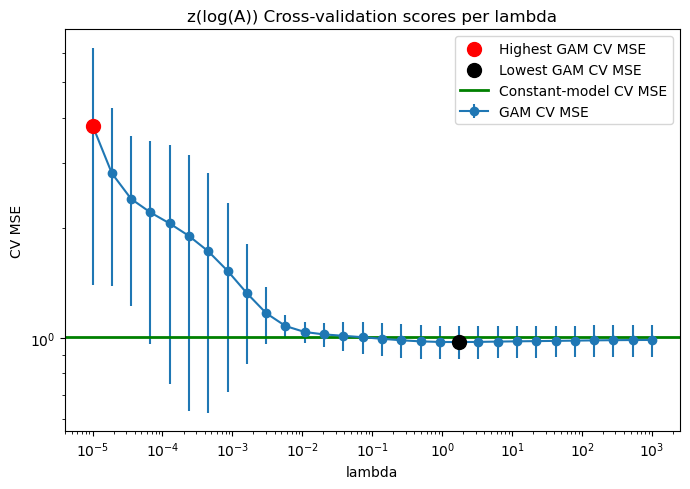

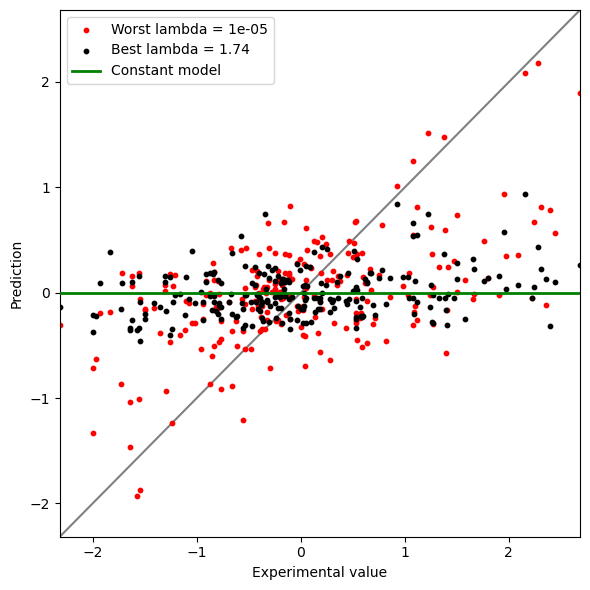

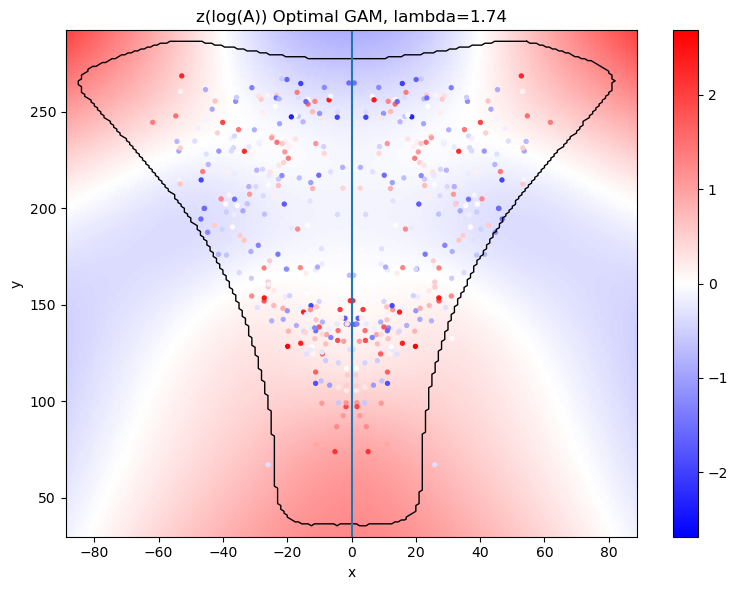

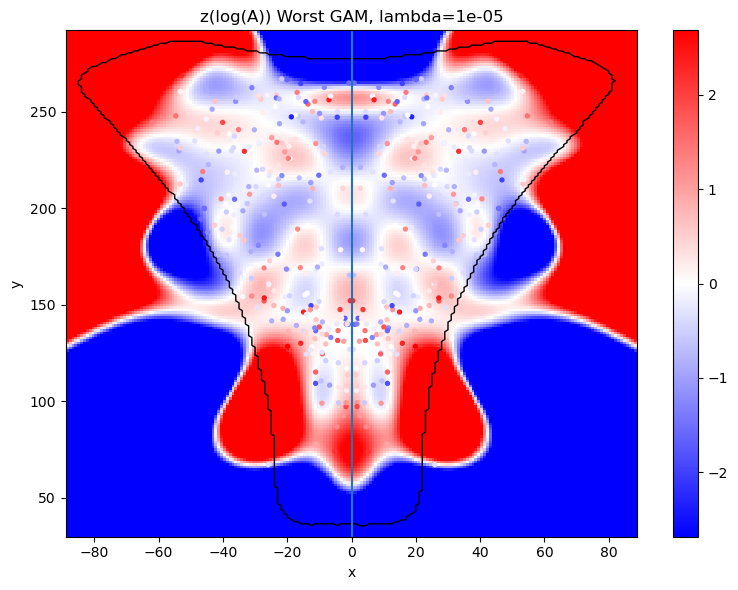

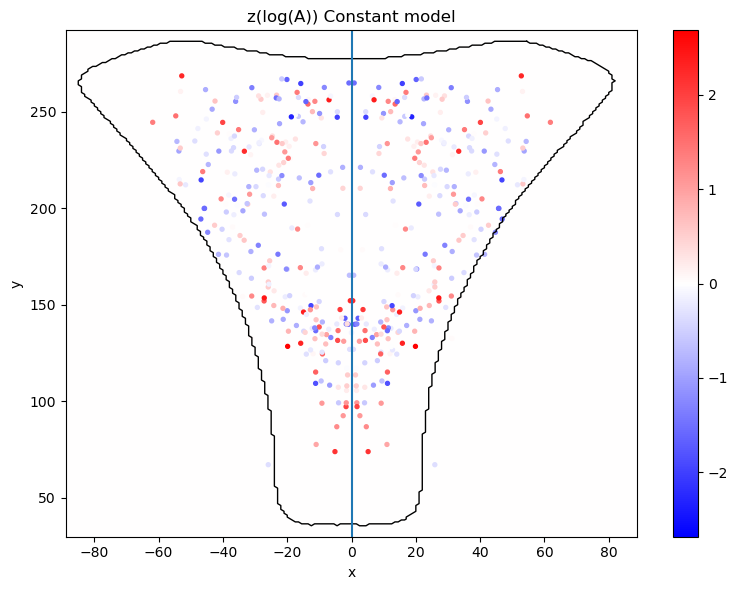

In [4]:
lims = [
    min(
        F.min(),
        F_fit_best.min(),
        F_fit_worst.min(),
        F_fit_constant.min(),
    ),
    max(
        F.max(),
        F_fit_best.max(),
        F_fit_worst.max(),
        F_fit_constant.max(),
    ),
]

nx = 200
ny = 200

x_grid = np.linspace(
    edge_knots[0][0],
    edge_knots[0][1],
    nx,
)

y_grid = np.linspace(
    edge_knots[1][0],
    edge_knots[1][1],
    ny,
)

xx, yy = np.meshgrid(
    x_grid,
    y_grid,
)

X_grid = np.column_stack([
    xx.ravel(),
    yy.ravel(),
])

F_grid_best = gam_best.predict(X_grid).reshape(ny, nx)
F_grid_worst = gam_worst.predict(X_grid).reshape(ny, nx)
F_grid_constant = np.full(
    (ny, nx),
    constant_value,
)

fig, ax = plt.subplots(figsize=(7, 5))

ax.errorbar(
    lambda_grid,
    mean_mse,
    yerr=std_mse,
    marker="o",
    label="GAM CV MSE",
)

ax.scatter(
    worst_lam,
    mean_mse[worst_idx],
    s=100,
    color="red",
    zorder=10,
    label="Highest GAM CV MSE",
)

ax.scatter(
    best_lam,
    mean_mse[best_idx],
    s=100,
    color="black",
    zorder=11,
    label="Lowest GAM CV MSE",
)

ax.axhline(
    constant_cv_mse,
    color="green",
    linewidth=2,
    label="Constant-model CV MSE",
)

ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel("lambda")
ax.set_ylabel("CV MSE")
ax.set_title(f"{F_name} Cross-validation scores per lambda")
ax.legend()

fig.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(6, 6))

ax.scatter(
    F,
    F_fit_worst,
    s=10,
    color="red",
    label=f"Worst lambda = {worst_lam:.3g}",
    zorder=1,
)

ax.scatter(
    F,
    F_fit_best,
    s=10,
    color="black",
    label=f"Best lambda = {best_lam:.3g}",
    zorder=2,
)

ax.axhline(
    constant_value,
    color="green",
    linewidth=2,
    label="Constant model",
    zorder=3,
)

ax.plot(
    lims,
    lims,
    "-",
    color="grey",
    zorder=0,
)

ax.set_xlim(lims)
ax.set_ylim(lims)
ax.set_xlabel("Experimental value")
ax.set_ylabel("Prediction")
ax.legend()

fig.tight_layout()
plt.show()

vmax = np.max(np.abs(F_sym))
vmin = -vmax

fig, ax = plt.subplots(figsize=(8, 6))

im = ax.pcolormesh(
    xx,
    yy,
    F_grid_best,
    shading="auto",
    cmap="bwr",
    vmin=vmin,
    vmax=vmax,
)

ax.scatter(
    x_sym,
    y_sym,
    s=8,
    c=F_sym,
    cmap="bwr",
    vmin=vmin,
    vmax=vmax,
)

ax.plot(
    border_x,
    border_y,
    "-k",
    lw=1,
)


ax.axvline(0)

ax.set_xlabel("x")
ax.set_ylabel("y")
ax.set_title(f"{F_name} Optimal GAM, lambda={best_lam:.3g}")

fig.colorbar(im, ax=ax)
fig.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(8, 6))

im = ax.pcolormesh(
    xx,
    yy,
    F_grid_worst,
    shading="auto",
    cmap="bwr",
    vmin=vmin,
    vmax=vmax,
)

ax.scatter(
    x_sym,
    y_sym,
    s=8,
    c=F_sym,
    cmap="bwr",
    vmin=vmin,
    vmax=vmax,
)

ax.plot(
    border_x,
    border_y,
    "-k",
    lw=1,
)


ax.axvline(0)

ax.set_xlabel("x")
ax.set_ylabel("y")
ax.set_title(f"{F_name} Worst GAM, lambda={worst_lam:.3g}")

fig.colorbar(im, ax=ax)
fig.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(8, 6))

im = ax.pcolormesh(
    xx,
    yy,
    F_grid_constant,
    shading="auto",
    cmap="bwr",
    vmin=vmin,
    vmax=vmax,
)

ax.scatter(
    x_sym,
    y_sym,
    s=8,
    c=F_sym,
    cmap="bwr",
    vmin=vmin,
    vmax=vmax,
)

ax.plot(
    border_x,
    border_y,
    "-k",
    lw=1,
)

ax.axvline(0)

ax.set_xlabel("x")
ax.set_ylabel("y")
ax.set_title(f"{F_name} Constant model")

fig.colorbar(im, ax=ax)
fig.tight_layout()
plt.show()

# Partition preview

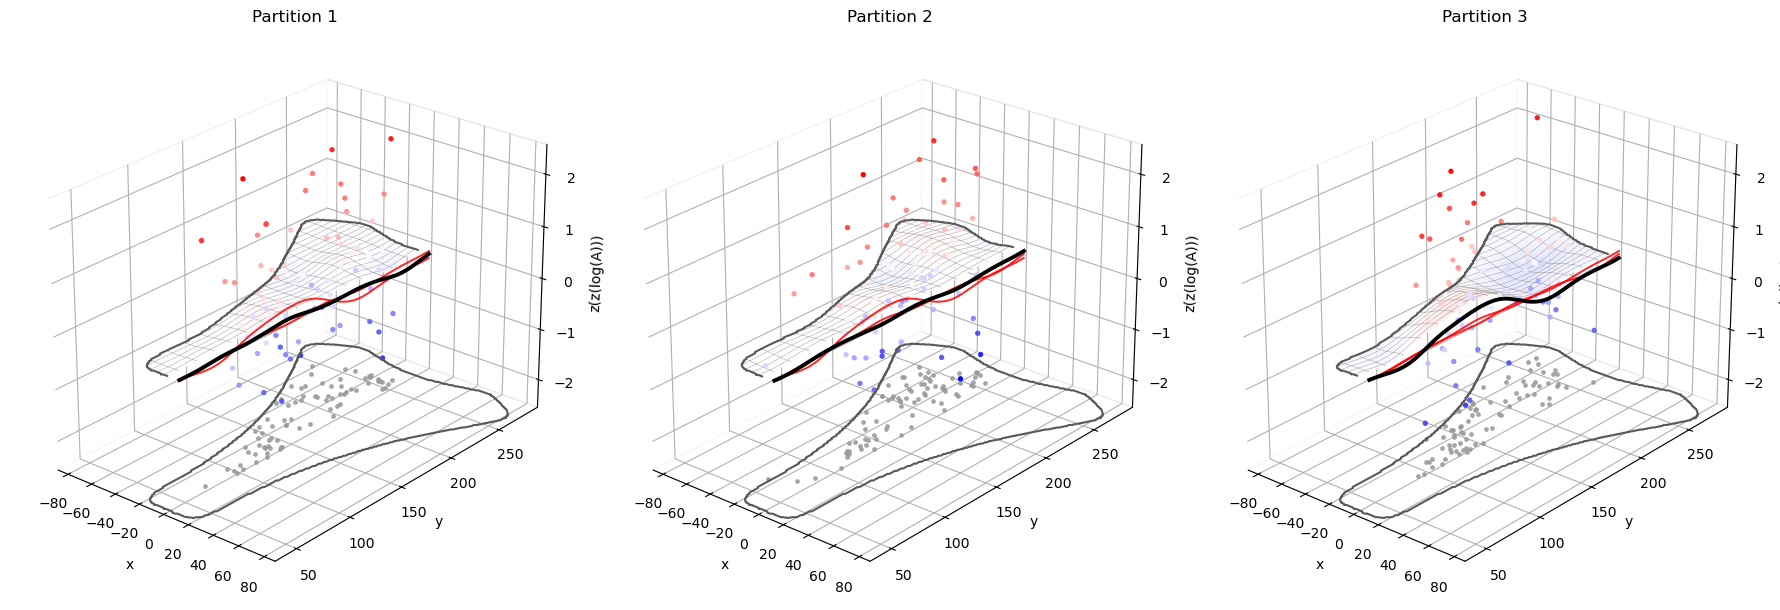

In [7]:
from matplotlib.path import Path

view_elev = 25
view_azim = -50
z_aspect_multiplier = 2.0

slice_x_offset_fraction = 0.05
active_slice_line_width = 2.8
inactive_slice_line_width = 1.4
inactive_slice_alpha = 0.85

nx = 200
ny = 200

spline_grid_stride = 12
spline_grid_linewidth = 0.35
spline_grid_alpha = 0.65

floor_point_size = 6
floor_point_alpha = 0.8

def plot_masked_wireframe(
    ax,
    X,
    Y,
    Z,
    mask,
    rstride,
    cstride,
    color,
    linewidth,
    alpha,
    zorder,
):
    def draw_segments(x_line, y_line, z_line, m_line):
        start = None

        for i, ok in enumerate(m_line):
            if ok and start is None:
                start = i
            if (not ok or i == len(m_line) - 1) and start is not None:
                end = i if not ok else i + 1
                if end - start >= 2:
                    ax.plot(
                        x_line[start:end],
                        y_line[start:end],
                        z_line[start:end],
                        color=color,
                        linewidth=linewidth,
                        alpha=alpha,
                        zorder=zorder,
                    )
                start = None

    for i in range(0, X.shape[0], rstride):
        draw_segments(
            X[i, :],
            Y[i, :],
            Z[i, :],
            mask[i, :],
        )

    for j in range(0, X.shape[1], cstride):
        draw_segments(
            X[:, j],
            Y[:, j],
            Z[:, j],
            mask[:, j],
        )

x_abs_max = max(
    abs(edge_knots[0][0]),
    abs(edge_knots[0][1]),
)

x_span = 2 * x_abs_max

y_span = (
    edge_knots[1][1]
    - edge_knots[1][0]
)

contour_path = Path(
    np.column_stack([
        border_x,
        border_y,
    ])
)

x_grid_left = np.linspace(
    -x_abs_max,
    0.0,
    nx,
)

y_grid_left = np.linspace(
    edge_knots[1][0],
    edge_knots[1][1],
    ny,
)

xx_left, yy_left = np.meshgrid(
    x_grid_left,
    y_grid_left,
)

X_grid_left = np.column_stack([
    xx_left.ravel(),
    yy_left.ravel(),
])

inside_grid = contour_path.contains_points(
    X_grid_left,
    radius=1e-9,
).reshape(ny, nx)

x0_model = np.zeros_like(y_grid_left)

slice_x_offset = (
    slice_x_offset_fraction
    * x_span
)

x0_plot = np.full_like(
    y_grid_left,
    slice_x_offset,
)

X0_line = np.column_stack([
    x0_model,
    y_grid_left,
])

inside_slice = contour_path.contains_points(
    X0_line,
    radius=1e-9,
)

border_mask = border_x <= 0

border_x_left = border_x[border_mask]
border_y_left = border_y[border_mask]

plot_data = []

for entry in independent_gams:
    subset_idx = entry["subset_idx"]

    x_subset = x[subset_idx]
    y_subset = y[subset_idx]
    F_subset_z = entry["F_z"]

    x_subset_sym = np.concatenate([
        x_subset,
        -x_subset,
    ])

    y_subset_sym = np.concatenate([
        y_subset,
        y_subset,
    ])

    F_subset_z_sym = np.concatenate([
        F_subset_z,
        F_subset_z,
    ])

    subset_left_mask = x_subset_sym <= 0

    x_subset_left = x_subset_sym[subset_left_mask]
    y_subset_left = y_subset_sym[subset_left_mask]
    F_subset_left_z = F_subset_z_sym[subset_left_mask]

    F_grid_partition_raw = entry["gam"].predict(
        X_grid_left
    ).reshape(ny, nx)

    F_grid_partition_z = np.ma.masked_where(
        ~inside_grid,
        F_grid_partition_raw,
    )

    F0_partition_z = entry["gam"].predict(
        X0_line
    )

    F0_partition_z = np.ma.masked_where(
        ~inside_slice,
        F0_partition_z,
    )

    border_partition_z = entry["gam"].predict(
        np.column_stack([
            border_x_left,
            border_y_left,
        ])
    )

    plot_data.append({
        "title": f"Partition {entry['partition_id']}",
        "x": x_subset_left,
        "y": y_subset_left,
        "F": F_subset_left_z,
        "grid": F_grid_partition_z,
        "grid_raw": F_grid_partition_raw,
        "slice": F0_partition_z,
        "border": border_partition_z,
    })

all_slices = [
    data["slice"]
    for data in plot_data
]

all_z_values = []

for data in plot_data:
    all_z_values.extend([
        np.asarray(data["F"]),
        np.asarray(data["grid"].compressed()),
        np.asarray(data["slice"].compressed()),
        np.asarray(data["border"]),
    ])

plot_z_max = max(
    np.max(np.abs(values))
    for values in all_z_values
    if values.size > 0
)

plot_z_min = -plot_z_max

z_visual_scale = (
    0.35
    * z_aspect_multiplier
    * max(x_span, y_span)
)

floor_outline_z = np.full_like(
    border_x,
    plot_z_min,
    dtype=float,
)

fig = plt.figure(
    figsize=(18, 6)
)

axes = [
    fig.add_subplot(
        1,
        3,
        i + 1,
        projection="3d",
        computed_zorder=False,
    )
    for i in range(3)
]

for active_idx, (ax, data) in enumerate(
    zip(axes, plot_data)
):
    ax.xaxis.pane.set_facecolor((1, 1, 1, 1))
    ax.yaxis.pane.set_facecolor((1, 1, 1, 1))
    ax.zaxis.pane.set_facecolor((1, 1, 1, 1))

    ax.xaxis.pane.set_alpha(1.0)
    ax.yaxis.pane.set_alpha(1.0)
    ax.zaxis.pane.set_alpha(1.0)

    ax.plot_surface(
        xx_left,
        yy_left,
        data["grid"],
        cmap="bwr",
        vmin=plot_z_min,
        vmax=plot_z_max,
        linewidth=0,
        antialiased=True,
        shade=False,
        alpha=1.0,
        zorder=1,
    )

    plot_masked_wireframe(
        ax=ax,
        X=xx_left,
        Y=yy_left,
        Z=data["grid_raw"],
        mask=inside_grid,
        rstride=spline_grid_stride,
        cstride=spline_grid_stride,
        color="0.45",
        linewidth=spline_grid_linewidth,
        alpha=spline_grid_alpha,
        zorder=2,
    )

    ax.scatter(
        data["x"],
        data["y"],
        np.full_like(data["x"], plot_z_min),
        s=floor_point_size,
        color="0.6",
        alpha=floor_point_alpha,
        depthshade=False,
        zorder=3,
    )

    ax.scatter(
        data["x"],
        data["y"],
        data["F"],
        s=8,
        c=data["F"],
        cmap="bwr",
        vmin=plot_z_min,
        vmax=plot_z_max,
        depthshade=False,
        zorder=4,
    )

    ax.plot(
        border_x_left,
        border_y_left,
        data["border"],
        color="0.35",
        lw=1.5,
        zorder=5,
    )

    ax.plot(
        border_x,
        border_y,
        floor_outline_z,
        color="0.35",
        lw=1.5,
        zorder=6,
    )

    for slice_idx, slice_z in enumerate(
        all_slices
    ):
        is_active = slice_idx == active_idx

        ax.plot(
            x0_plot,
            y_grid_left,
            slice_z,
            color=(
                "black"
                if is_active
                else "red"
            ),
            lw=(
                active_slice_line_width
                if is_active
                else inactive_slice_line_width
            ),
            alpha=(
                1.0
                if is_active
                else inactive_slice_alpha
            ),
            zorder=(
                201
                if is_active
                else 200
            ),
        )

    ax.set_xlim(
        -x_abs_max,
        x_abs_max,
    )

    ax.set_ylim(
        edge_knots[1][0],
        edge_knots[1][1],
    )

    ax.set_zlim(
        plot_z_min,
        plot_z_max,
    )

    ax.set_box_aspect((
        x_span,
        y_span,
        z_visual_scale,
    ))

    ax.view_init(
        elev=view_elev,
        azim=view_azim,
    )

    ax.set_xlabel("x")
    ax.set_ylabel("y")
    ax.set_zlabel(f"z({F_name})")
    ax.set_title(data["title"])

fig.tight_layout()
plt.show()

# Export for partition plot

In [8]:
import pickle
import numpy as np
from matplotlib.path import Path

export_filename = "../output/adjusted_lambda_splines.pkl"

view_elev = 25
view_azim = -50
z_aspect_multiplier = 2.0

slice_x_offset_fraction = 0.05
active_slice_line_width = 2.8
inactive_slice_line_width = 1.4
inactive_slice_alpha = 0.85

nx = 200
ny = 200

spline_grid_stride = 12
spline_grid_linewidth = 0.35
spline_grid_alpha = 0.65

floor_point_size = 6
floor_point_alpha = 0.8

x_abs_max = max(
    abs(edge_knots[0][0]),
    abs(edge_knots[0][1]),
)

x_span = 2 * x_abs_max

y_span = (
    edge_knots[1][1]
    - edge_knots[1][0]
)

contour_path = Path(
    np.column_stack([
        border_x,
        border_y,
    ])
)

x_grid_left = np.linspace(
    -x_abs_max,
    0.0,
    nx,
)

y_grid_left = np.linspace(
    edge_knots[1][0],
    edge_knots[1][1],
    ny,
)

xx_left, yy_left = np.meshgrid(
    x_grid_left,
    y_grid_left,
)

X_grid_left = np.column_stack([
    xx_left.ravel(),
    yy_left.ravel(),
])

inside_grid = contour_path.contains_points(
    X_grid_left,
    radius=1e-9,
).reshape(ny, nx)

x0_model = np.zeros_like(y_grid_left)

slice_x_offset = (
    slice_x_offset_fraction
    * x_span
)

x0_plot = np.full_like(
    y_grid_left,
    slice_x_offset,
)

X0_line = np.column_stack([
    x0_model,
    y_grid_left,
])

inside_slice = contour_path.contains_points(
    X0_line,
    radius=1e-9,
)

border_mask = border_x <= 0

border_x_left = border_x[border_mask]
border_y_left = border_y[border_mask]

plot_data = []

for entry in independent_gams:
    subset_idx = entry["subset_idx"]

    x_subset = x[subset_idx]
    y_subset = y[subset_idx]
    F_subset_z = entry["F_z"]

    x_subset_sym = np.concatenate([
        x_subset,
        -x_subset,
    ])

    y_subset_sym = np.concatenate([
        y_subset,
        y_subset,
    ])

    F_subset_z_sym = np.concatenate([
        F_subset_z,
        F_subset_z,
    ])

    subset_left_mask = x_subset_sym <= 0

    x_subset_left = x_subset_sym[subset_left_mask]
    y_subset_left = y_subset_sym[subset_left_mask]
    F_subset_left_z = F_subset_z_sym[subset_left_mask]

    F_grid_partition_raw = entry["gam"].predict(
        X_grid_left
    ).reshape(ny, nx)

    F0_partition_raw = entry["gam"].predict(
        X0_line
    )

    border_partition_z = entry["gam"].predict(
        np.column_stack([
            border_x_left,
            border_y_left,
        ])
    )

    plot_data.append({
        "title": f"Partition {entry['partition_id']}",
        "partition_id": int(entry["partition_id"]),
        "lambda": float(entry["lam"]),
        "x": np.asarray(x_subset_left, dtype=float),
        "y": np.asarray(y_subset_left, dtype=float),
        "F": np.asarray(F_subset_left_z, dtype=float),
        "grid_raw": np.asarray(F_grid_partition_raw, dtype=float),
        "slice_raw": np.asarray(F0_partition_raw, dtype=float),
        "border": np.asarray(border_partition_z, dtype=float),
    })

all_z_values = []

for data in plot_data:
    grid_inside = data["grid_raw"][inside_grid]
    slice_inside = data["slice_raw"][inside_slice]

    all_z_values.extend([
        data["F"],
        grid_inside,
        slice_inside,
        data["border"],
    ])

plot_z_max = max(
    np.max(np.abs(values))
    for values in all_z_values
    if values.size > 0
)

plot_z_min = -plot_z_max

z_visual_scale = (
    0.35
    * z_aspect_multiplier
    * max(x_span, y_span)
)

export_data = {
    "F_name": str(F_name),
    "view_elev": float(view_elev),
    "view_azim": float(view_azim),
    "z_aspect_multiplier": float(z_aspect_multiplier),
    "slice_x_offset_fraction": float(slice_x_offset_fraction),
    "active_slice_line_width": float(active_slice_line_width),
    "inactive_slice_line_width": float(inactive_slice_line_width),
    "inactive_slice_alpha": float(inactive_slice_alpha),
    "spline_grid_stride": int(spline_grid_stride),
    "spline_grid_linewidth": float(spline_grid_linewidth),
    "spline_grid_alpha": float(spline_grid_alpha),
    "floor_point_size": float(floor_point_size),
    "floor_point_alpha": float(floor_point_alpha),
    "nx": int(nx),
    "ny": int(ny),
    "x_abs_max": float(x_abs_max),
    "x_span": float(x_span),
    "y_span": float(y_span),
    "z_visual_scale": float(z_visual_scale),
    "plot_z_min": float(plot_z_min),
    "plot_z_max": float(plot_z_max),
    "edge_knots": np.asarray(edge_knots, dtype=float),
    "border_x": np.asarray(border_x, dtype=float),
    "border_y": np.asarray(border_y, dtype=float),
    "border_x_left": np.asarray(border_x_left, dtype=float),
    "border_y_left": np.asarray(border_y_left, dtype=float),
    "x_grid_left": np.asarray(x_grid_left, dtype=float),
    "y_grid_left": np.asarray(y_grid_left, dtype=float),
    "xx_left": np.asarray(xx_left, dtype=float),
    "yy_left": np.asarray(yy_left, dtype=float),
    "inside_grid": np.asarray(inside_grid, dtype=bool),
    "inside_slice": np.asarray(inside_slice, dtype=bool),
    "x0_plot": np.asarray(x0_plot, dtype=float),
    "plot_data": plot_data,
}

with open(export_filename, "wb") as f:
    pickle.dump(
        export_data,
        f,
        protocol=pickle.HIGHEST_PROTOCOL,
    )

print(export_filename)

adjusted_lambda_splines.pkl
